In [1]:
from qibo import set_backend
import numpy as np
from collections import Counter
import time
set_backend("qibojit", platform="cuda")


import square as square_direct_inversion
import square_opt as square_optimized

[Qibo 0.3.5|INFO|2026-11-04 17:33:23]: Using qibojit (numba) backend on /CPU:0


In [2]:
def build_circuit(m):
    _circ, _ = square_direct_inversion.Square(m, input_swaps = False, method = 'ripple_no_input_carry')
    return _circ

def build_circuit_opt(m):
    _circ, _ = square_optimized.Square(m, input_swaps = False)
    return _circ

In [3]:
results = {name: {"m": [], "nqubits": [], "t": [], "t_sd": [], "gates": [], "by_type": [], "depth":[]} for name in ['direct_inversion', 'optimized']}

In [4]:
name = 'direct_inversion'
m_range = np.arange(2, 7, 1)
reps = 1

for m in m_range:
    m = int(m);print(m)
    circ = build_circuit(m)

    times = []
    for r in range(reps):
        start = time.time()
        circ()
        stop = time.time()
        times.append(stop - start)
    t = np.mean(times)
    t_sd = np.std(times)
    by_type = Counter(type(g).__name__ for g in circ.queue)
    r = results[name]
    r["m"].append(m); r["t"].append(t); r["t_sd"].append(t_sd)
    r["gates"].append(len(circ.queue)); r["by_type"].append(dict(by_type)); r["depth"].append(circ.depth); r["nqubits"].append(circ.nqubits)



2
3
4
5
6


In [ ]:
name = 'optimized'
m_range = np.arange(2, 14, 1)
reps = 1

for m in m_range:
    m = int(m);print(m)
    circ = build_circuit_opt(m)

    times = []
    #for r in range(reps):
        #start = time.time()
        #circ()
        #stop = time.time()
        #times.append(stop - start)
    times.append(0)
    t = np.mean(times)
    t_sd = np.std(times)
    by_type = Counter(type(g).__name__ for g in circ.queue)
    r = results[name]
    r["m"].append(m); r["t"].append(t); r["t_sd"].append(t_sd)
    r["gates"].append(len(circ.queue)); r["by_type"].append(dict(by_type)); r["depth"].append(circ.depth); r["nqubits"].append(circ.nqubits)

2
3
4
5
6
7
8
9


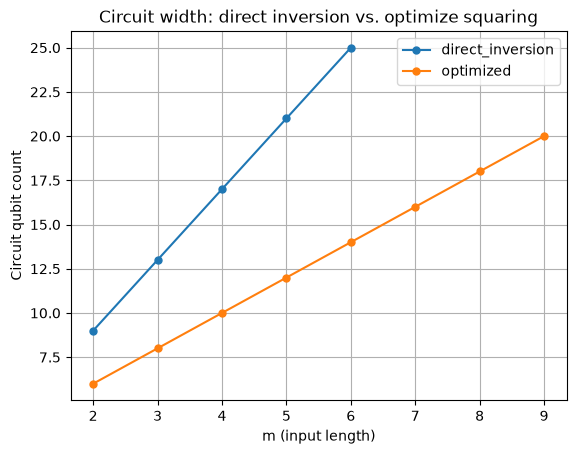

In [6]:
import matplotlib.pyplot as plt
plt.plot(results['direct_inversion']['m'], results['direct_inversion']['nqubits'], marker="o", markersize = 5, label = 'direct_inversion')
plt.plot(results['optimized']['m'], results['optimized']['nqubits'], marker="o", markersize = 5, label = 'optimized')
plt.xlabel('m (input length)')
plt.ylabel('Circuit qubit count')
plt.title('Circuit width: direct inversion vs. optimize squaring')
plt.legend()
plt.grid()
plt.show()

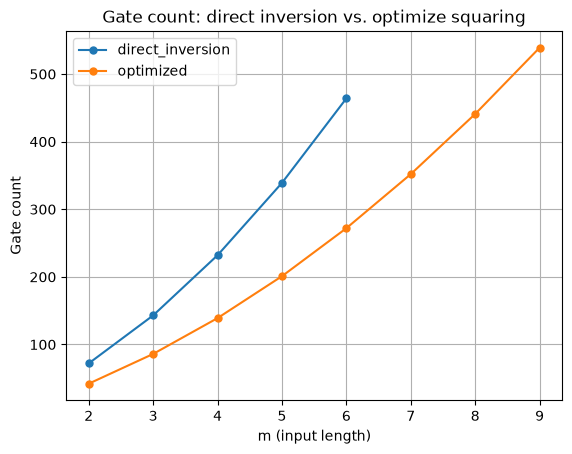

In [7]:
plt.plot(results['direct_inversion']['m'], results['direct_inversion']['gates'], marker="o", markersize = 5, label = 'direct_inversion')
plt.plot(results['optimized']['m'], results['optimized']['gates'], marker="o", markersize = 5, label = 'optimized')
plt.xlabel('m (input length)')
plt.ylabel('Gate count')
plt.title('Gate count: direct inversion vs. optimize squaring')
plt.legend()
plt.grid()
plt.show()

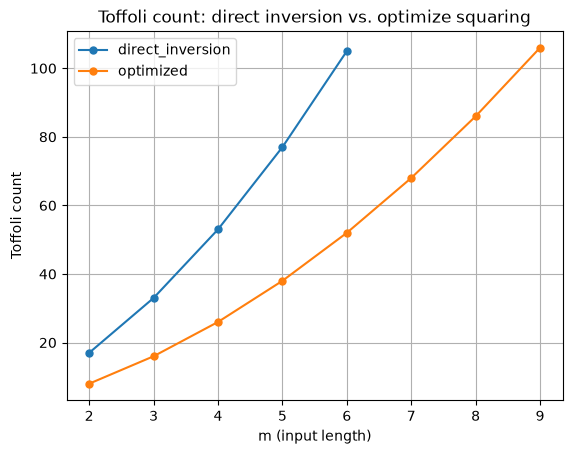

In [8]:
plt.plot(results['direct_inversion']['m'], [results['direct_inversion']['by_type'][k]['TOFFOLI'] for k in range(0, len(results['direct_inversion']['by_type']))], marker="o", markersize = 5, label = 'direct_inversion')
plt.plot(results['optimized']['m'], [results['optimized']['by_type'][k]['TOFFOLI'] for k in range(0, len(results['optimized']['by_type']))], marker="o", markersize = 5, label = 'optimized')
plt.xlabel('m (input length)')
plt.ylabel('Toffoli count')
plt.title('Toffoli count: direct inversion vs. optimize squaring')
plt.legend()
plt.grid()
plt.show()

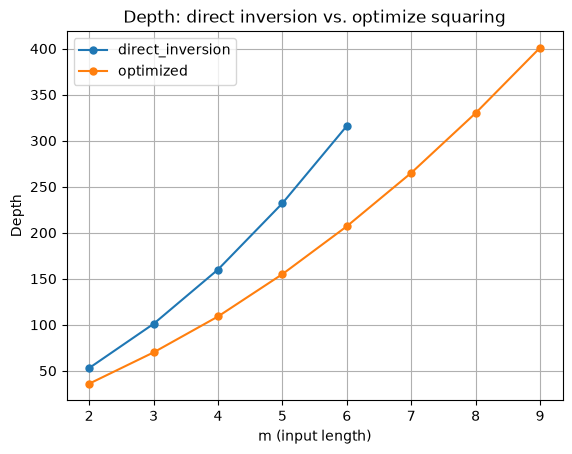

In [9]:
plt.plot(results['direct_inversion']['m'], results['direct_inversion']['depth'], marker="o", markersize = 5, label = 'direct_inversion')
plt.plot(results['optimized']['m'], results['optimized']['depth'], marker="o", markersize = 5, label = 'optimized')
plt.xlabel('m (input length)')
plt.ylabel('Depth')
plt.title('Depth: direct inversion vs. optimize squaring')
plt.legend()
plt.grid()
plt.show()

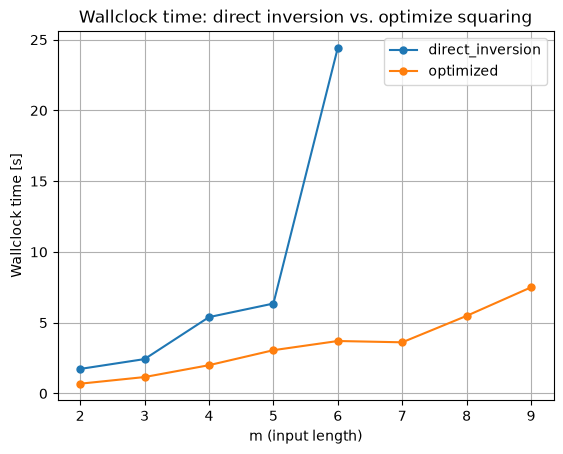

In [10]:
plt.plot(results['direct_inversion']['m'], results['direct_inversion']['t'], marker="o", markersize = 5, label = 'direct_inversion')
plt.plot(results['optimized']['m'], results['optimized']['t'], marker="o", markersize = 5, label = 'optimized')
plt.xlabel('m (input length)')
plt.ylabel('Wallclock time [s]')
plt.title('Wallclock time: direct inversion vs. optimize squaring')
plt.legend()
plt.grid()
plt.show()

In [11]:
gates = results['optimized']['gates']
mm = results['optimized']['m']

from scipy.optimize import curve_fit

def poly(x, a0, a1, a2):
    y = a0 + a1*x + a2*x**2
    return y

print('Gate count scaling (optimized):')
param, cov = curve_fit(poly, mm, gates)
for i in range(len(param)):
    print(f'a{i} : {param[i]}')



Gate count scaling (optimized):
a0 : -19.000000000000057
a1 : 21.50000000000001
a2 : 4.5


In [12]:
toffolis = [results['optimized']['by_type'][k]['TOFFOLI'] for k in range(0, len(results['optimized']['by_type']))]
mm = results['optimized']['m']

print('Toffoli count scaling (optimized):')
param, cov = curve_fit(poly, mm, toffolis)
for i in range(len(param)):
    print(f'a{i} : {param[i]}')

Toffoli count scaling (optimized):
a0 : -1.9999999999999931
a1 : 2.9999999999999964
a2 : 1.0000000000000004


In [13]:
cnots = [results['optimized']['by_type'][k]['CNOT'] for k in range(0, len(results['optimized']['by_type']))]
mm = results['optimized']['m']

print('CNOT count scaling (optimized):')
param, cov = curve_fit(poly, mm, cnots)
for i in range(len(param)):
    print(f'a{i} : {param[i]}')

CNOT count scaling (optimized):
a0 : -15.999999999999993
a1 : 14.499999999999995
a2 : 3.5000000000000004


In [14]:
xs = [results['optimized']['by_type'][k]['X'] for k in range(0, len(results['optimized']['by_type']))]
mm = results['optimized']['m']

print('X count scaling (optimized):')
param, cov = curve_fit(poly, mm, xs)
for i in range(len(param)):
    print(f'a{i} : {param[i]}')

X count scaling (optimized):
a0 : -0.9999999999999795
a1 : 3.999999999999991
a2 : 7.771561172376096e-16


/tmp/ipykernel_120340/3639715547.py:5: OptimizeWarning: Covariance of the parameters could not be estimated
  param, cov = curve_fit(poly, mm, xs)


In [15]:
depth = results['optimized']['depth']
mm = results['optimized']['m']

print('Depth scaling (optimized):')
param, cov = curve_fit(poly, mm, depth)
for i in range(len(param)):
    print(f'a{i} : {param[i]}')

Depth scaling (optimized):
a0 : -11.410714285714242
a1 : 17.57738095238094
a2 : 3.1369047619047636


In [16]:
circ.nqubits

20

In [18]:
nqubits = results['optimized']['nqubits']
mm = results['optimized']['m']

print('Width scaling (optimized):')
param, cov = curve_fit(poly, mm, nqubits)
for i in range(len(param)):
    print(f'a{i} : {param[i]}')

Width scaling (optimized):
a0 : 2.0000000000000173
a1 : 1.9999999999999927
a2 : 6.661338147750939e-16


/tmp/ipykernel_120340/45127329.py:5: OptimizeWarning: Covariance of the parameters could not be estimated
  param, cov = curve_fit(poly, mm, nqubits)
